**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



## Import data

In [2]:
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "summary"
)
vec = dir(txt_fdiry)
for (txt in vec){cat(txt, "\n")}

region.phenograph.coverage.encode_chipseq_full_log2p.cluster.tsv 
region.phenograph.coverage.encode_chipseq_full_log2p.summary.tsv 
region.umap.metric_euclidean.neighbors_070.coverage.encode_chipseq_full_log2p.tsv 


In [3]:
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "summary"
)
txt_fname = "region.umap.metric_euclidean.neighbors_070.coverage.encode_chipseq_full_log2p.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

dat = read_tsv(txt_fpath, show_col_types = FALSE)

dat_region_umap = dat
print(dim(dat))
head(dat)

[1] 33953     6


Chrom,ChromStart,ChromEnd,Region,UMAP1,UMAP2
<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>
chr1,100036895,100039189,chr1:100036895-100039189,7.914342,5.290927
chr1,100132375,100133491,chr1:100132375-100133491,9.109111,5.825063
chr1,100248956,100250290,chr1:100248956-100250290,7.182062,6.236031
chr1,100265562,100266994,chr1:100265562-100266994,7.761321,5.706240
chr1,10032429,10033763,chr1:10032429-10033763,9.426987,4.859900
chr1,100351018,100353268,chr1:100351018-100353268,7.974018,5.128401


In [4]:
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "summary"
)
txt_fname = "region.phenograph.coverage.encode_chipseq_full_log2p.cluster.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

dat = read_tsv(txt_fpath, show_col_types = FALSE)

dat_region_cluster = dat
print(dim(dat))
head(dat)

[1] 33953     9


Region,Cluster_k30,Cluster_k40,Cluster_k50,Cluster_k60,Cluster_k70,Cluster_k80,Cluster_k90,Cluster_k100
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr1:605104-605675,8,10,8,7,7,7,7,7
chr1:778233-779389,6,6,0,0,0,0,0,0
chr1:818708-819335,13,4,8,7,7,5,5,5
chr1:826796-828040,0,6,0,0,0,0,0,0
chr1:842516-843431,1,8,1,1,1,1,1,1
chr1:903783-905204,0,7,3,4,6,6,4,4


In [5]:
dat = dplyr::inner_join(
    dat_region_umap,
    dat_region_cluster,
    by = "Region"
)

dat_region_merge = dat
print(dim(dat))
fun_display_table(head(dat))

[1] 33953    14


Chrom,ChromStart,ChromEnd,Region,UMAP1,UMAP2,Cluster_k30,Cluster_k40,Cluster_k50,Cluster_k60,Cluster_k70,Cluster_k80,Cluster_k90,Cluster_k100
chr1,100036895,100039189,chr1:100036895-100039189,7.914342,5.290927,0,0,0,0,0,0,0,0
chr1,100132375,100133491,chr1:100132375-100133491,9.109111,5.825063,6,6,0,0,0,0,0,0
chr1,100248956,100250290,chr1:100248956-100250290,7.182062,6.236031,0,6,7,11,1,0,0,0
chr1,100265562,100266994,chr1:100265562-100266994,7.761321,5.706240,0,0,0,0,0,0,0,0
chr1,10032429,10033763,chr1:10032429-10033763,9.426987,4.859900,17,16,15,16,14,13,14,14
chr1,100351018,100353268,chr1:100351018-100353268,7.974018,5.128401,0,0,0,0,0,0,0,0


In [6]:
dat = dat_region_merge
dat = dat %>%
    tidyr::pivot_longer(
        cols = starts_with("Cluster_k"),
        names_to  = "k",
        values_to = "cluster") %>%
    dplyr::mutate(k = gsub("Cluster_k", "k=", k))

dat = dat %>% dplyr::mutate(k = factor(k, levels = paste0("k=", seq(30, 100, by = 10))))
head(dat)

Chrom,ChromStart,ChromEnd,Region,UMAP1,UMAP2,k,cluster
<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<fct>,<dbl>
chr1,100036895,100039189,chr1:100036895-100039189,7.914342,5.290927,k=30,0
chr1,100036895,100039189,chr1:100036895-100039189,7.914342,5.290927,k=40,0
chr1,100036895,100039189,chr1:100036895-100039189,7.914342,5.290927,k=50,0
chr1,100036895,100039189,chr1:100036895-100039189,7.914342,5.290927,k=60,0
chr1,100036895,100039189,chr1:100036895-100039189,7.914342,5.290927,k=70,0
chr1,100036895,100039189,chr1:100036895-100039189,7.914342,5.290927,k=80,0


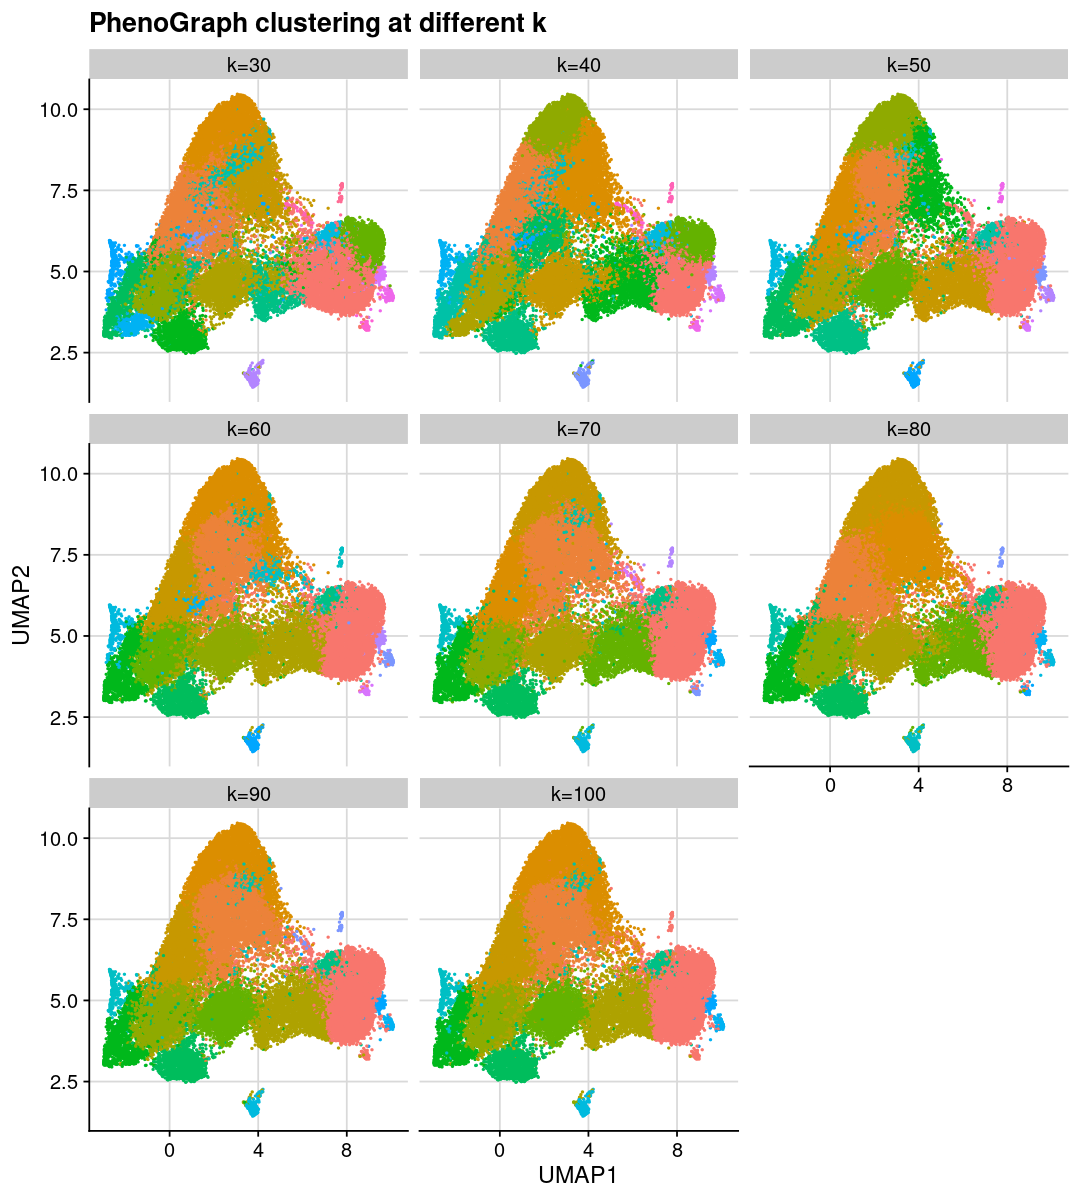

In [14]:
gpt <- ggplot(dat, aes(x = UMAP1, y = UMAP2, color = as.factor(cluster))) +
  geom_point(size = 0.1) +
  facet_wrap(~k) +
  theme_cowplot() +
  background_grid() +
  theme(legend.position = "none") +
  labs(title = "PhenoGraph clustering at different k",
       color = "Cluster")

options(repr.plot.height = 10, repr.plot.width = 9)
print(gpt)

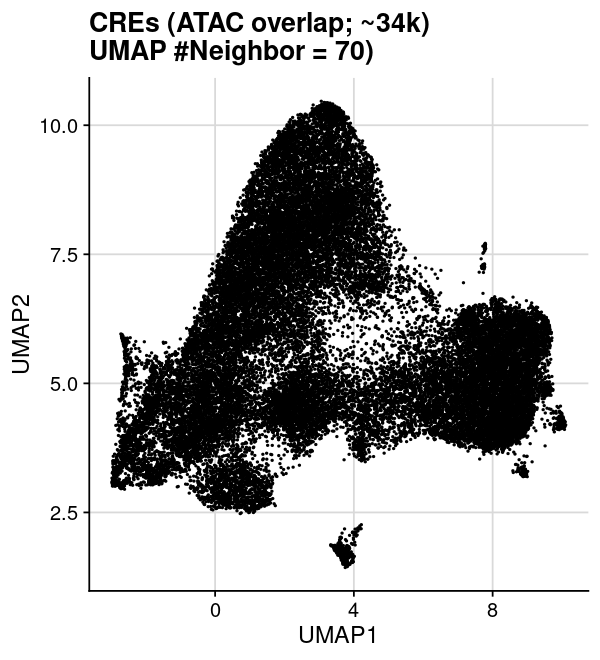

In [22]:
dat = dat_region_merge

gpt = ggplot(dat, aes(x=UMAP1, y=UMAP2)) + 
    geom_point(size=0.1) + 
    theme_cowplot() +
    background_grid() +
    labs(title = "CREs (ATAC overlap; ~34k)\nUMAP #Neighbor = 70)") +
    theme(legend.position = "none")

options(repr.plot.height = 5.5, repr.plot.width = 5)
print(gpt)

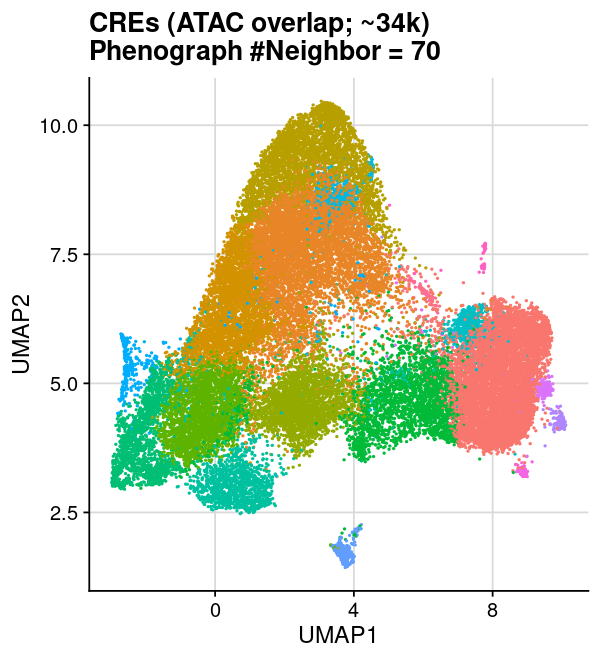

In [21]:
dat = dat_region_merge
dat = dat %>% 
    dplyr::mutate(Cluster = paste("Cluster", Cluster_k70, sep = ": ")) %>%
    dplyr::mutate(Cluster = factor(Cluster, levels = paste("Cluster", sort(unique(Cluster_k70)), sep = ": ")))

gpt = ggplot(dat, aes(x=UMAP1, y=UMAP2, color = Cluster)) + 
    geom_point(size=0.1) + 
    theme_cowplot() +
    background_grid() +
    labs(title = "CREs (ATAC overlap; ~34k)\nPhenograph #Neighbor = 70") +
    theme(legend.position = "none")

options(repr.plot.height = 5.5, repr.plot.width = 5)
print(gpt)

In [22]:
dat = dat_region_merge
head(dat)

Chrom,ChromStart,ChromEnd,Region,UMAP1,UMAP2,Cluster_k30,Cluster_k40,Cluster_k50,Cluster_k60,Cluster_k70,Cluster_k80,Cluster_k90,Cluster_k100
<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr1,100036895,100039189,chr1:100036895-100039189,7.914342,5.290927,0,0,0,0,0,0,0,0
chr1,100132375,100133491,chr1:100132375-100133491,9.109111,5.825063,6,6,0,0,0,0,0,0
chr1,100248956,100250290,chr1:100248956-100250290,7.182062,6.236031,0,6,7,11,1,0,0,0
chr1,100265562,100266994,chr1:100265562-100266994,7.761321,5.706240,0,0,0,0,0,0,0,0
chr1,10032429,10033763,chr1:10032429-10033763,9.426987,4.859900,17,16,15,16,14,13,14,14
chr1,100351018,100353268,chr1:100351018-100353268,7.974018,5.128401,0,0,0,0,0,0,0,0


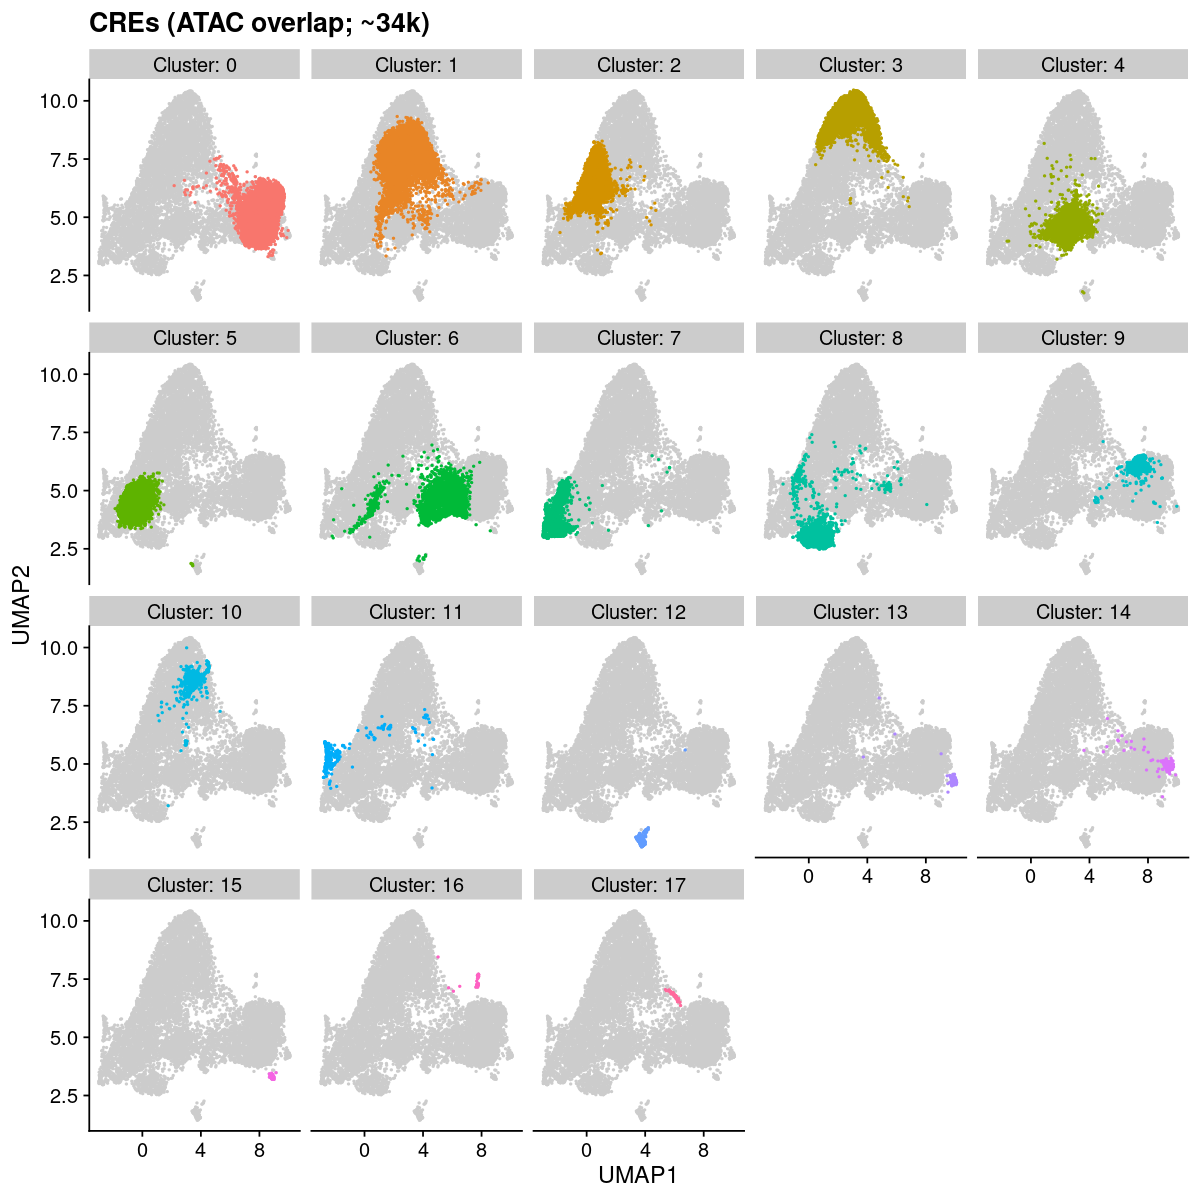

In [39]:
dat = dat_region_merge
dat = dat %>% 
    dplyr::mutate(Cluster = paste("Cluster", Cluster_k70, sep = ": ")) %>%
    dplyr::mutate(Cluster = factor(Cluster, levels = paste("Cluster", sort(unique(Cluster_k70)), sep = ": ")))

set.seed(123)
dat_bg = dat %>% dplyr::select(UMAP1, UMAP2) %>% dplyr::slice_sample(n = 10000)
dat_fg = dat %>% dplyr::select(UMAP1, UMAP2, Cluster)

gpt = ggplot() + 
    geom_point(data = dat_bg, size=0.1, aes(x=UMAP1, y=UMAP2), color = "grey80") +
    geom_point(data = dat_fg, size=0.1, aes(x=UMAP1, y=UMAP2,  color = Cluster)) + 
    theme_cowplot() +
    labs(title = "CREs (ATAC overlap; ~34k)") +
    facet_wrap(~Cluster) +
    theme(legend.position = "none")
    
options(repr.plot.height = 10, repr.plot.width = 10)
print(gpt)

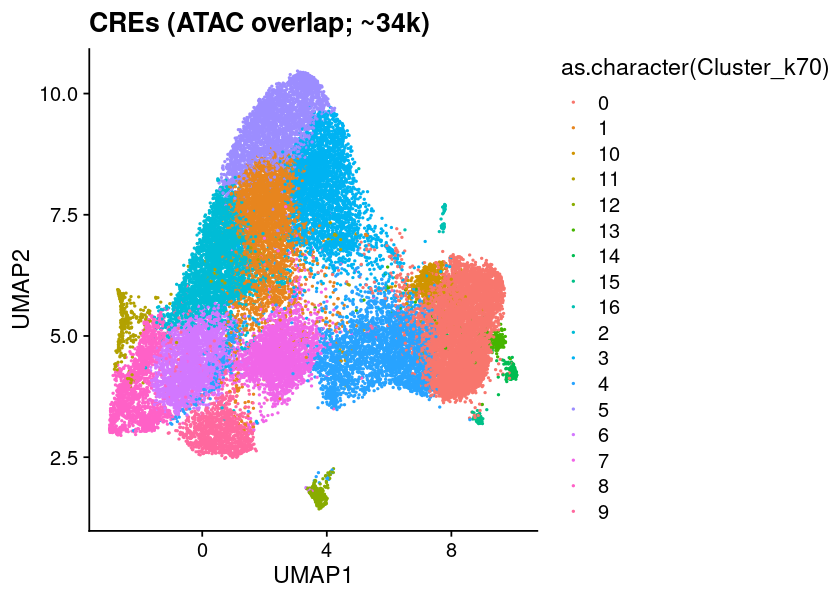

In [7]:
dat = dplyr::inner_join(
    dat_region_umap,
    dat_region_cluster,
    by = "Region"
)

gpt = ggplot(dat, aes(x=UMAP1, y=UMAP2, color = as.character(Cluster_k70))) + 
    geom_point(size=0.1) + 
    theme_cowplot() +
    labs(title = "CREs (ATAC overlap; ~34k)")
options(repr.plot.height = 5, repr.plot.width = 7)
print(gpt)

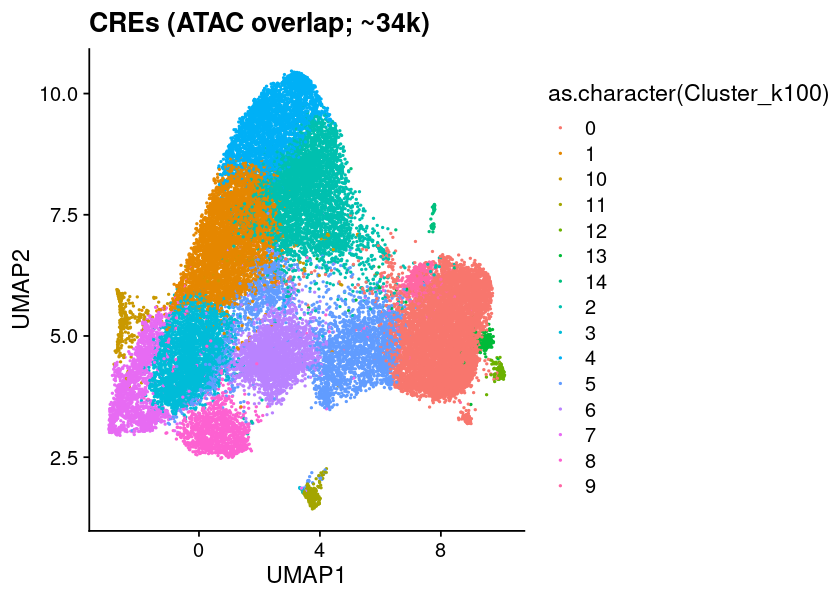

In [8]:
dat = dplyr::inner_join(
    dat_region_umap,
    dat_region_cluster,
    by = "Region"
)

gpt = ggplot(dat, aes(x=UMAP1, y=UMAP2, color = as.character(Cluster_k100))) + 
    geom_point(size=0.1) + 
    theme_cowplot() +
    labs(title = "CREs (ATAC overlap; ~34k)")
options(repr.plot.height = 5, repr.plot.width = 7)
print(gpt)